# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'saumyap2'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

In [2]:
# 1a: your work here
p1a_d = load('p1a_extinction')
airm = p1a_d['airmass'].to_numpy()
zpm = p1a_d['zeropoint_mag'].to_numpy()
sigma_y = p1a_d['sigma_quoted_mag'].to_numpy()
N = len(airm)

A = np.vstack([np.ones(N), airm]).T

Sinv = np.diag(1.0 / sigma_y**2)

ATSinvA = A.T @ Sinv @ A
cov_wls = np.linalg.inv(ATSinvA)
theta_w = cov_wls @ (A.T @ Sinv @ zpm)

m0 = theta_w[0]
k = theta_w[1]

sigma_m0 = np.sqrt(cov_wls[0, 0])
sigma_k = np.sqrt(cov_wls[1, 1])

print("\nWLS fit:")
print(f"  k = {k:.2f} ± {sigma_k:.2f}")
print(f"  m0  = {m0:.2f} ± {sigma_m0:.2f}")

p, cov_p = np.polyfit(airm, zpm, 1, w=1/sigma_y, cov=True)
k_poly      = p[0]          # slope
sig_k_poly  = np.sqrt(cov_p[0,0])

print("\nPolyfit:")
print(f"  k = {k_poly:.4f} ± {sig_k_poly:.4f}")

chi2 = np.sum(((zpm - A @ theta_w) / sigma_y)**2)  # not reduced
dof  = N - 2
chi2nu = chi2 / dof
print("\n")
print(f"chi2 = {chi2:.3}")

p_low = stats.chi2.cdf(chi2, dof)
p_high = stats.chi2.sf(chi2, dof)
p_two = 2 * min(p_low, p_high)

print("\n")
print(f"reduced chi2 = {chi2nu:.3f}")
print(f"P(chi2 <= observed) = {100*p_low:.4f}%")
print(f"P(chi2 >= observed) = {p_high:.4f}")
print(f"Two-sided tail probability = {p_two:.4f}")


WLS fit:
  k = 0.15 ± 0.01
  m0  = 25.00 ± 0.02

Polyfit:
  k = 0.1500 ± 0.0039


chi2 = 1.91


reduced chi2 = 0.147
P(chi2 <= observed) = 0.0174%
P(chi2 >= observed) = 0.9998
Two-sided tail probability = 0.0003


**ANSWER:**

2. polyfit with cov=True computes tbe same WLS covariance but then it rescales it with the reduced chi-square. The cov docs say the covariance is scaled by the residual sum of squares divided by the degrees of freedom. Our quoted errors only WLS error assumes $\chi^2$ = 1. It assumes the supplied uncertainties are reliable relative to one another, but their overall scale may be wrong.
3. I got $\chi^2=1.91$ with 15-2 = 13 degrees of freedom, giving a reduced chi-square of 0.147. Assuming the linear model is correct and the quoted errors represent independent Gaussian standard deviations, the probability of obtaining a chi-square this small or smaller is $P(\chi^2\leq1.91)=0.000174$, or 0.017%. This is extremely unlikely under the assumed error model, indicating that the residuals are much smaller than expected from the pipeline uncertainties.
4. I would quote $k=0.1500\pm0.0039$ mag/airmass, provided the quoted errors are miscalibrated by a common factor and the observations are independent. The reduced chi-square is 0.147, much smaller than the expected value of 1, and the probability of obtaining such a small chi-square is only 0.017%. This suggests that the pipeline has overestimated the measurement uncertainties. Polyfit rescales the covariance using the observed residual scatter, reducing the slope uncertainty by a factor of 0.383. However, this smaller error bar is justified only if the low chi-square really results from overestimated uncertainties rather than correlations or another problem with the error model.

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [3]:
# 1b: your work here

p1b_d = load("p1b_centroid")
N = p1b_d['n_photons'].to_numpy()

sigma_psf = p1b_d['psf_sigma_arcsec'].to_numpy()
sigma_quoted = p1b_d['quoted_sigma_x0_arcsec'].to_numpy()

I_x0 = N / sigma_psf**2

sigma_crb = np.sqrt(1 / I_x0)

print(f"Number of photons = {N[0]:.2f}")
print(f"PSF width = {sigma_psf[0]:.4f} arcsec")
print(f"Quoted centroid uncertainty = {sigma_quoted[0]:.4f} arcsec")
print(f"Cramér-Rao bound = {sigma_crb[0]:.2f} arcsec")

Number of photons = 362.00
PSF width = 1.4491 arcsec
Quoted centroid uncertainty = 0.0508 arcsec
Cramér-Rao bound = 0.08 arcsec


**ANSWER:**

No, the quoted uncertainty of 0.0508 arcsec is smaller than the Cramér–Rao bound of 0.076 arcsec, so it is not possible as a valid 1σ uncertainty for an unbiased estimator under the assumed model. The classmate's number must represent an underestimated uncertainty or a different quantity, rather than the true sampling uncertainty of the centroid. Two possible mistakes are incorrectly treating correlated measurements as independent photons, or using the wrong normalization when calculating the weighted mean's uncertainty.

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

In [4]:
# 1c: your work here
p1c_d = load('p1c_profile')

depth = p1c_d['depth_ppt'].to_numpy()
minus2lnL = p1c_d['minus2lnL'].to_numpy()

i_min = np.argmin(minus2lnL)

idx = np.argsort(np.abs(depth - depth[i_min]))[:5]

a, b, c = np.polyfit(depth[idx] - depth[i_min], minus2lnL[idx], 2)

best_depth = depth[i_min] - b / (2 * a)

curvature = 2 * a

sigma_correct = np.sqrt(2 / curvature)

sigma_classmate = 1 / np.sqrt(curvature)

# Compare
factor = sigma_correct / sigma_classmate

print(f"Best-fit depth = {best_depth:.4f} ppt")
print(f"Curvature = {curvature:.4f} ppt^-2")
print(f"Correct 1-sigma uncertainty = {sigma_correct:.4f} ppt")
print(f"Classmate's uncertainty = {sigma_classmate:.4f} ppt")

print(f"FINAL: Depth = {best_depth:.4f} ± {sigma_correct:.4f} ppt\n")

Best-fit depth = 1.6127 ppt
Curvature = 54.8395 ppt^-2
Correct 1-sigma uncertainty = 0.1910 ppt
Classmate's uncertainty = 0.1350 ppt
FINAL: Depth = 1.6127 ± 0.1910 ppt



In [5]:
i_min = np.argmin(minus2lnL)
depth_min = depth[i_min]
target = minus2lnL[i_min] + 1

i_left = np.where(minus2lnL[:i_min] >= target)[0][-1]
i_right = np.where(minus2lnL[i_min:] >= target)[0][0] + i_min

depth_lower = np.interp(
    target,
    minus2lnL[i_left:i_left+2][::-1],
    depth[i_left:i_left+2][::-1]
)

depth_upper = np.interp(
    target,
    minus2lnL[i_right-1:i_right+1],
    depth[i_right-1:i_right+1]
)

sigma_minus = depth_min - depth_lower
sigma_plus = depth_upper - depth_min

asymmetry = abs(sigma_plus - sigma_minus) / ((sigma_plus + sigma_minus) / 2)


print(f"Best depth (grid minimum) = {depth_min:.4f} ppt")
print(f"Lower 1-sigma bound = {depth_lower:.4f} ppt")
print(f"Upper 1-sigma bound = {depth_upper:.4f} ppt")

print(f"\nProfile result = {depth_min:.4f} (+{sigma_plus:.4f} / -{sigma_minus:.4f}) ppt")
print(f"Curvature result = {best_depth:.4f} ± {sigma_correct:.4f} ppt")

print(f"\nRelative asymmetry = {asymmetry:.2%}")

print("\nComparison:")
print(f"Lower-side uncertainty: {sigma_minus:.4f} ppt")
print(f"Upper-side uncertainty: {sigma_plus:.4f} ppt")
print(f"Curvature uncertainty: {sigma_correct:.4f} ppt")
print("The curvature estimate assumes a locally quadratic likelihood,")
print("while the direct profile interval allows asymmetric uncertainties.")

Best depth (grid minimum) = 1.6127 ppt
Lower 1-sigma bound = 1.4213 ppt
Upper 1-sigma bound = 1.8033 ppt

Profile result = 1.6127 (+0.1906 / -0.1914) ppt
Curvature result = 1.6127 ± 0.1910 ppt

Relative asymmetry = 0.45%

Comparison:
Lower-side uncertainty: 0.1914 ppt
Upper-side uncertainty: 0.1906 ppt
Curvature uncertainty: 0.1910 ppt
The curvature estimate assumes a locally quadratic likelihood,
while the direct profile interval allows asymmetric uncertainties.


In [6]:
z = sigma_classmate / sigma_correct
predicted_coverage = 2 * stats.norm.cdf(z) - 1

print(f"Predicted coverage = {predicted_coverage:.2%}")

Predicted coverage = 52.05%


In [7]:
true_depth = 1.6127

sigma_correct = 0.1910
sigma_classmate = 0.1350


rng = np.random.default_rng(42)
n_sim = 5000

fake_depths = rng.normal(true_depth, sigma_correct, n_sim)

lower = fake_depths - sigma_classmate
upper = fake_depths + sigma_classmate

contains_truth = (lower <= true_depth) & (true_depth <= upper)

simulated_coverage = np.mean(contains_truth)

coverage_error = np.sqrt(
    simulated_coverage * (1 - simulated_coverage) / n_sim
)


print(f"True depth = {true_depth:.4f} ppt")
print(f"Correct sigma = {sigma_correct:.4f} ppt")
print(f"Classmate sigma = {sigma_classmate:.4f} ppt")
print(f"Number of simulations = {n_sim}\n")

print(f"Predicted coverage = {predicted_coverage:.2%}")
print(f"Simulated coverage = {simulated_coverage:.2%} ± {coverage_error:.2%}")
print("Expected coverage with correct sigma = 68.27%")



True depth = 1.6127 ppt
Correct sigma = 0.1910 ppt
Classmate sigma = 0.1350 ppt
Number of simulations = 5000

Predicted coverage = 52.05%
Simulated coverage = 52.74% ± 0.71%
Expected coverage with correct sigma = 68.27%


**ANSWER:**

1. The classmate's error bar is incorrect. It is too small by a factor of 1.4142. For a Gaussian likelihood, the 1-sigma interval satisfies Delta(-2lnL) = 1. Since the quadratic expansion is (1/2)* curvature * (depth-best_depth)^2, the correct uncertainty is sqrt(2/curvature), not 1/sqrt(curvature).
2. The profile interval is approximately symmetric within 5%. This is very close to curvature answer of 0.1910
3. The classmate's intervals contain the true depth about 52% of the time becaue their uncertainty is underestimated by sqrt(2).

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

In [8]:
# 1d: your work here
p1d_d = load('p1d_mass_samples')

mass = p1d_d['M2_Msun'].to_numpy()

mass_16, mass_median, mass_84 = np.percentile(mass, [16, 50, 84])

sigma_minus = mass_median - mass_16
sigma_plus = mass_84 - mass_median

print(f"16th percentile = {mass_16:.4f} M_sun")
print(f"84th percentile = {mass_84:.4f} M_sun")

print(f"\nLower uncertainty = {sigma_minus:.4f} M_sun")
print(f"Upper uncertainty = {sigma_plus:.4f} M_sun")

print(f"\nFINAL: M2 = {mass_median:.4f} (+{sigma_plus:.4f} / -{sigma_minus:.4f}) M_sun")

16th percentile = 8.2937 M_sun
84th percentile = 14.0490 M_sun

Lower uncertainty = 2.4910 M_sun
Upper uncertainty = 3.2643 M_sun

FINAL: M2 = 10.7846 (+3.2643 / -2.4910) M_sun


In [9]:
N = len(mass)

std = np.std(mass, ddof=1)
variance = np.var(mass, ddof=1)

width = mass_84 - mass_16

sem = std / np.sqrt(N)

sigma_ref = width / 2


print(f"Reference 1-sigma = {sigma_ref:.4f} M_sun\n")

print("(i) Variance")
print(f"Value = {variance:.4f} M_sun^2")
print("Not a 1-sigma error bar: wrong units (M_sun^2).\n")

print("(ii) 84th - 16th percentile")
print(f"Value = {width:.4f} M_sun")
print(f"Factor too large = {width / sigma_ref:.2f}\n")

print("(iii) Standard deviation / sqrt(N)")
print(f"Value = {sem:.6f} M_sun")
print(f"Factor too small = {sigma_ref / sem:.2f}")

Reference 1-sigma = 2.8776 M_sun

(i) Variance
Value = 9.1479 M_sun^2
Not a 1-sigma error bar: wrong units (M_sun^2).

(ii) 84th - 16th percentile
Value = 5.7553 M_sun
Factor too large = 2.00

(iii) Standard deviation / sqrt(N)
Value = 0.033815 M_sun
Factor too small = 85.10


Lower uncertainty = 2.4910 M_sun
Upper uncertainty = 3.2643 M_sun
Relative asymmetry = 26.87%
Skewness = 0.841


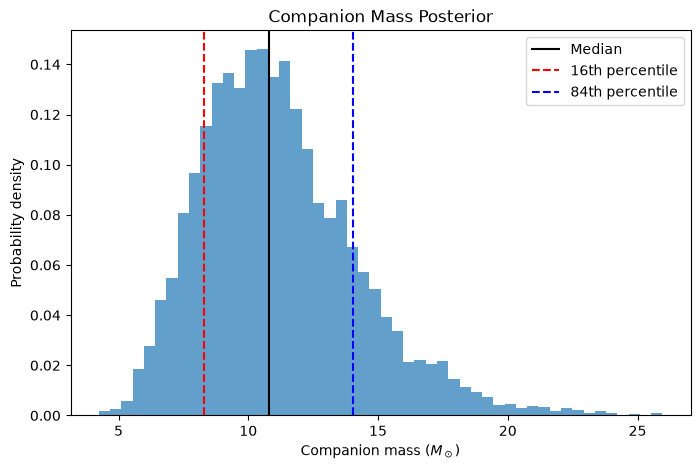

In [10]:
asymmetry = abs(sigma_plus - sigma_minus) / ((sigma_plus + sigma_minus) / 2)
skewness = stats.skew(mass)

print(f"Lower uncertainty = {sigma_minus:.4f} M_sun")
print(f"Upper uncertainty = {sigma_plus:.4f} M_sun")
print(f"Relative asymmetry = {asymmetry:.2%}")
print(f"Skewness = {skewness:.3f}")

plt.figure(figsize=(8, 5))
plt.hist(mass, bins=50, density=True, alpha=0.7)
plt.axvline(mass_median, color='black', label='Median')
plt.axvline(mass_16, color='red', linestyle='--', label='16th percentile')
plt.axvline(mass_84, color='blue', linestyle='--', label='84th percentile')

plt.xlabel(r'Companion mass ($M_\odot$)')
plt.ylabel('Probability density')
plt.title('Companion Mass Posterior')
plt.legend()
plt.show()

**ANSWER:**

(i) Variance: Measures the squared spread of the posterior samples. It is not a valid 1sigma error bar, so there is no meaningful factor because the units are different. Taking its square root gives the standard deviation.
   
(ii) 84th−16th percentile: This is the full width of the central 68% credible interval. For an approximately Gaussian posterior, it is about 2 times too large to use as a symmetric 1sigma error bar.



(iii) Standard deviation /sqrt(8000): This approximates the Monte Carlo standard error of the posterior sample mean, assuming independent samples. It is about 85 times too small as an uncertainty on the companion mass.

3. a symmetric error bar is not appropriate since the posterier is skewed to the right.

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

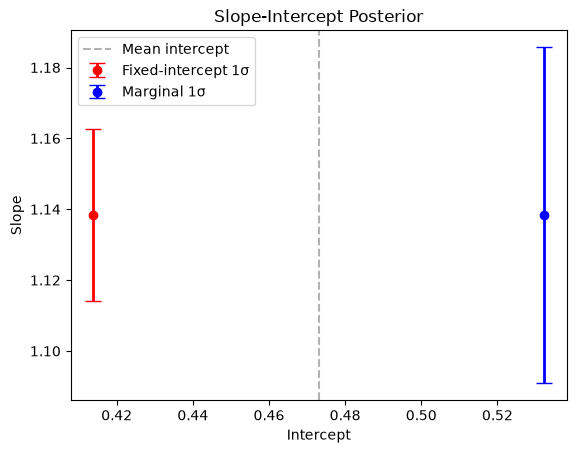

In [14]:
d = load('p1e_slope_intercept_samples')

slope = d['slope'].to_numpy()
intercept = d['intercept'].to_numpy()

sigma_slope = np.std(slope, ddof=1)
sigma_intercept = np.std(intercept, ddof=1)

# Correlation coefficient
rho = np.corrcoef(slope, intercept)[0, 1]

# Conditional uncertainty at fixed intercept (Gaussian approximation)
sigma_fixed = sigma_slope * np.sqrt(1 - rho**2)
sigma_marginal = sigma_slope

# Ratio
ratio = sigma_fixed / sigma_marginal


slope_center = np.mean(slope)
intercept_center = np.mean(intercept)

offset = 0.2 * sigma_intercept

plt.errorbar(intercept_center - offset, slope_center,
             yerr=sigma_fixed, fmt='o', color='red',
             capsize=6, linewidth=2, label='Fixed-intercept 1σ')

plt.errorbar(intercept_center + offset, slope_center,
             yerr=sigma_marginal, fmt='o', color='blue',
             capsize=6, linewidth=2, label='Marginal 1σ')

plt.axvline(intercept_center, color='gray', linestyle='--',
            alpha=0.6, label='Mean intercept')

plt.xlabel('Intercept')
plt.ylabel('Slope')
plt.title('Slope-Intercept Posterior')
plt.legend()
plt.show()

**ANSWER:**

$\frac{\sigma_{fixed}}{\sigma_{marginal}} = \sqrt{1-\rho^2}$

The fixed-intercept uncertainty is the conditional uncertainty, while the marginalized uncertainty accounts for variation in both parameters. Their ratio depends on the magnitude of the correlation: $\rho=0$, the uncertainties are equal; as $|\rho|$ approaches 1, the fixed-intercept uncertainty becomes much smaller.

The classmate's error bar is appropriate only when the intercept is known exactly and held fixed, rather than estimated from the same data.

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

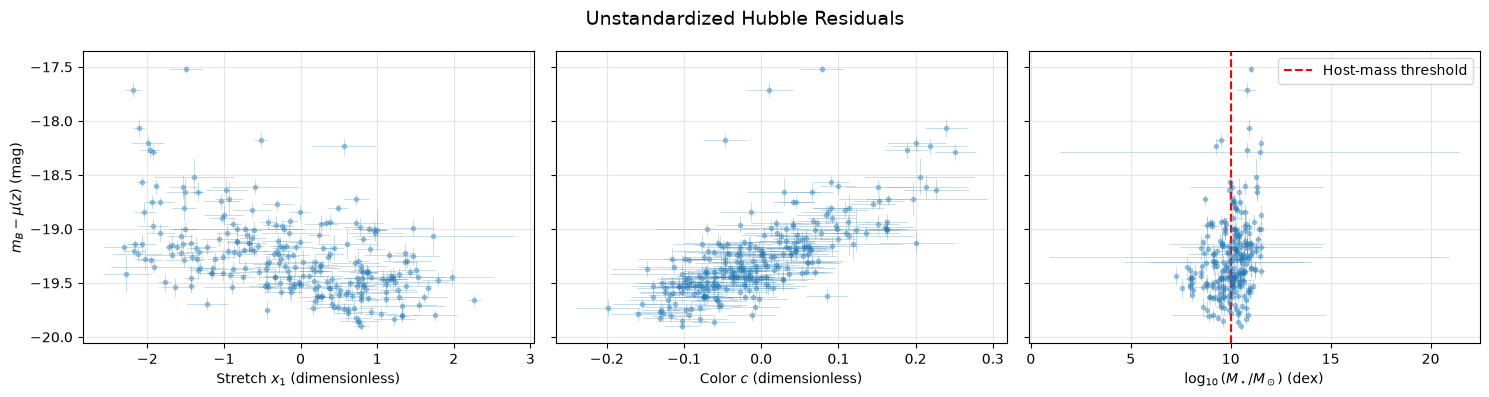

In [15]:
# 2a: your work here
from astropy.cosmology import FlatLambdaCDM
from astropy.constants import c as c_light

sne = load('p2_pantheon_sne')

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
z = sne['z'].to_numpy()
mu = cosmo.distmod(z).value

hubble_res = sne['mB'].to_numpy() - mu

sigma_mu_pec = (5 / np.log(10)) * (250 / c_light.to_value('km/s')) / z

sigma_res = np.sqrt(sne['mB_err'].to_numpy()**2 + sigma_mu_pec**2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

columns = ['x1', 'c', 'host_logmass']
errors = ['x1_err', 'c_err', 'host_logmass_err']
labels = [
    r'Stretch $x_1$ (dimensionless)',
    r'Color $c$ (dimensionless)',
    r'$\log_{10}(M_\star/M_\odot)$ (dex)'
]

for ax, col, err, label in zip(axes, columns, errors, labels):
    ax.errorbar(
        sne[col], hubble_res,
        xerr=sne[err],
        yerr=sigma_res,
        fmt='o',
        markersize=3,
        alpha=0.35,
        elinewidth=0.5,
        capsize=0
    )

    ax.set_xlabel(label)
    ax.grid(alpha=0.3)

axes[2].axvline(10, color='red', linestyle='--',
                label='Host-mass threshold')
axes[2].legend()

axes[0].set_ylabel(r'$m_B - \mu(z)$ (mag)')

fig.suptitle('Unstandardized Hubble Residuals', fontsize=14)
plt.tight_layout()
plt.show()

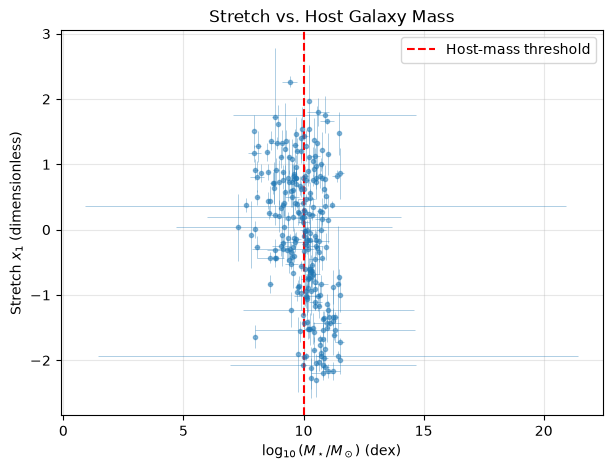

In [16]:
plt.figure(figsize=(7, 5))

plt.errorbar(
    sne['host_logmass'],
    sne['x1'],
    xerr=sne['host_logmass_err'],
    yerr=sne['x1_err'],
    fmt='o',
    markersize=3,
    alpha=0.5,
    elinewidth=0.5,
    capsize=0
)

plt.axvline(10, color='red', linestyle='--',
            label='Host-mass threshold')

plt.xlabel(r'$\log_{10}(M_\star/M_\odot)$ (dex)')
plt.ylabel(r'Stretch $x_1$ (dimensionless)')
plt.title('Stretch vs. Host Galaxy Mass')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**ANSWER:**

2. The x1 plot trends down linearly while the c plot trends up linearly, which follows the Tripp relation. The $-\alpha x_1$ term makes broad light curve supernovae brighter and the color term $\beta c$ makes redder supernovae fainter.
3. The plot shows that supernovae in higher-mass galaxies generally have smaller stretch x1. Since smaller stretch corresponds to fainter supernovae, this can make the raw Hubble residuals increase with host mass, potentially masking or reversing the negative host-mass step $\gamma$.
4. Yes, a few supernovae have unusually large positive Hubble residuals and lie noticeably above the main distribution, making them possible contaminants. Some apparent outliers may be explained by the effects of stretch and color.
5. $\alpha$ has units of magnitudes per unit stretch, and $\beta$ has units of magnitudes per unit color. Since x1 and c are dimensionless, they just have units of magnitude.

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

Potential contaminants: 3 SNe

16259: residual = 1.377 +/- 0.093 mag, significance = 14.8 sigma
2000cf: residual = 1.180 +/- 0.101 mag, significance = 11.7 sigma
2006mo: residual = 1.292 +/- 0.106 mag, significance = 12.2 sigma


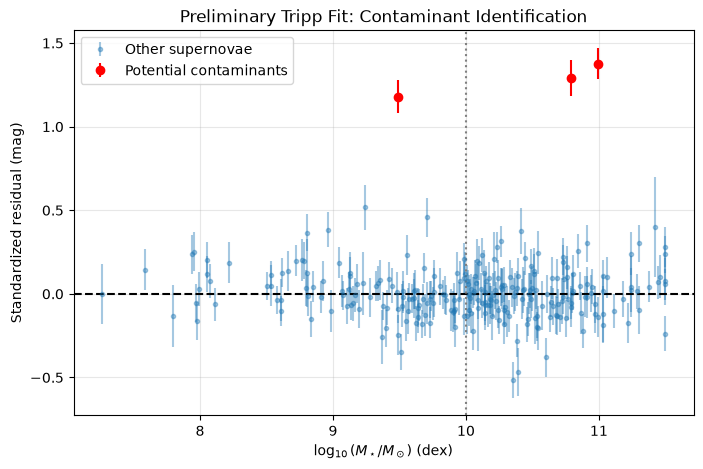

Original sample: 250 SNe
Cleaned sample: 247 SNe


In [17]:
# 2b: your work here
from scipy.optimize import minimize
from scipy.stats import t

# Extract the required data
mB = sne['mB'].to_numpy()
x1 = sne['x1'].to_numpy()
c = sne['c'].to_numpy()
host_mass = sne['host_logmass'].to_numpy()

mB_err = sne['mB_err'].to_numpy()
x1_err = sne['x1_err'].to_numpy()
c_err = sne['c_err'].to_numpy()

cov_mB_x1 = sne['cov_mB_x1'].to_numpy()
cov_mB_c = sne['cov_mB_c'].to_numpy()
cov_x1_c = sne['cov_x1_c'].to_numpy()

# Host-mass step
high_mass = (host_mass > 10).astype(float)

# Full propagated variance
def total_variance(alpha, beta, sigma_int):
    return (
        mB_err**2
        + alpha**2 * x1_err**2
        + beta**2 * c_err**2
        + 2 * alpha * cov_mB_x1
        - 2 * beta * cov_mB_c
        - 2 * alpha * beta * cov_x1_c
        + sigma_mu_pec**2
        + sigma_int**2
    )

# Tripp residuals
def tripp_residuals(theta):
    M, alpha, beta, gamma, sigma_int = theta

    return (
        mB - mu - M
        + alpha * x1
        - beta * c
        - gamma * high_mass
    )

def robust_nll(theta):
    M, alpha, beta, gamma, sigma_int = theta

    variance = total_variance(alpha, beta, sigma_int)

    if np.any(variance <= 0):
        return np.inf

    sigma = np.sqrt(variance)
    residuals = tripp_residuals(theta)

    return -np.sum(
        t.logpdf(residuals / sigma, df=3) - np.log(sigma)
    )

theta0 = [-19.3, 0.14, 3.0, -0.06, 0.12]

bounds = [
    (-21, -17),  # M
    (0, 0.5),    # alpha
    (0, 6),      # beta
    (-0.5, 0.5), # gamma
    (0, 0.5)     # sigma_int
]

result = minimize(
    robust_nll,
    theta0,
    method='L-BFGS-B',
    bounds=bounds
)

if not result.success:
    raise RuntimeError(result.message)

theta_robust = result.x

r = tripp_residuals(theta_robust)

sigma = np.sqrt(
    total_variance(
        theta_robust[1],
        theta_robust[2],
        theta_robust[4]
    )
)

normalized_residuals = r / sigma

threshold = 5.0
contaminants = normalized_residuals > threshold

print(f"Potential contaminants: {np.sum(contaminants)} SNe")
print()

for i in np.where(contaminants)[0]:
    print(
        f"{sne.iloc[i]['name']}: "
        f"residual = {r[i]:.3f} +/- {sigma[i]:.3f} mag, "
        f"significance = {normalized_residuals[i]:.1f} sigma"
    )

plt.figure(figsize=(8, 5))

plt.errorbar(
    host_mass[~contaminants],
    r[~contaminants],
    yerr=sigma[~contaminants],
    fmt='o',
    markersize=3,
    alpha=0.4,
    label='Other supernovae'
)

plt.errorbar(
    host_mass[contaminants],
    r[contaminants],
    yerr=sigma[contaminants],
    fmt='o',
    color='red',
    markersize=6,
    label='Potential contaminants'
)

plt.axhline(0, color='black', linestyle='--')
plt.axvline(10, color='gray', linestyle=':')

plt.xlabel(r'$\log_{10}(M_\star/M_\odot)$ (dex)')
plt.ylabel('Standardized residual (mag)')
plt.title('Preliminary Tripp Fit: Contaminant Identification')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

clean_mask = ~contaminants

sne_clean = sne.loc[clean_mask].copy()
mu_clean = mu[clean_mask]
sigma_mu_pec_clean = sigma_mu_pec[clean_mask]

print(f"Original sample: {len(sne)} SNe")
print(f"Cleaned sample: {len(sne_clean)} SNe")

**ANSWER:**

1. $v^T C_i v = \sigma_{m_B,i}^2 + \alpha^2 \sigma_{x_1,i}^2 + \beta^2 \sigma_{c,i}^2 \\
+ 2\alpha\mathrm{Cov}(m_B,x_1)_i \\
- 2\beta\mathrm{Cov}(m_B,c)_i \\
- 2\alpha\beta\mathrm{Cov}(x_1,c)_i$

The off-diagonal terms account for correlations between $m_B$, $x_1$, and $c$ from the same SALT2 light-curve fit, which affect the propagated uncertainty in the standardized magnitude.

2. $\ln {L(\theta} = -\frac{1}{2}\sum_{i=1}^{N} [ \frac{r_i^2}{\sigma_i^2} +\ln(2\pi\sigma_i^2)]$

where

$ r_i = m_{B,i} - \mu(z_i) - M + \alpha x_{1,i} - \beta c_i - \gamma\Theta_i $

3. I would use broad, uniform priors for all five parameters so the data can determine their values without overly restrictive assumptions.

- $M \sim (-21,-17)\ \mathrm{mag}$:
  A broad range covering the expected absolute magnitude
  of Type Ia supernovae.

- $\alpha \sim (0,0.5)\ \mathrm{mag}/x_1$:
  Positive because larger stretch corresponds to brighter
  supernovae.

- $\beta \sim (0,6)\ \mathrm{mag}/c$:
  Positive because redder supernovae tend to be fainter.

- $\gamma \sim (-0.5,0.5)\ \mathrm{mag}$:
  Allows both positive and negative host-mass steps,
  including no step at all.

- $\sigma_{\mathrm{int}} \sim (0,0.5)\ \mathrm{mag}$:
  Intrinsic scatter must be nonnegative, while the upper
  bound allows a broad range of possible scatter.


4. I choose to sample $\sigma_{\mathrm{int}}$ directly because it is consistent with my uniform prior and allows the intrinsic scatter to be zero. I enforce $\sigma_{\mathrm{int}}\geq0$ through the prior bounds.

5. I would identify potential contaminants using a robust fit and look for supernovae with unusually large standardized residuals relative to their uncertainties. I would remove only clearly identified outliers before fitting the final model. However, removing data reduces the sample size and may introduce selection bias, especially if the removed supernovae are associated with particular host masses. It can also underestimate the intrinsic scatter and make the final uncertainties appear smaller than they should be.

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

/Users/saumyapatel/conda/envs/astr457/lib/python3.14/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [M, alpha, beta, gamma, sigma_int]


Output()

Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 11 seconds.


MAP estimates (uncertainties from posterior SD):
M: -19.275 +/- 0.014 mag
alpha: 0.1311 +/- 0.0094 mag/stretch
beta: 2.89 +/- 0.11 mag/color
gamma: -0.039 +/- 0.019 mag
sigma_int: 0.1109 +/- 0.0084 mag

Convergence diagnostics:
           r_hat  ess_bulk  ess_tail
M            1.0    5857.0    5551.0
alpha        1.0    7601.0    6035.0
beta         1.0    7893.0    5168.0
gamma        1.0    5594.0    5895.0
sigma_int    1.0    7992.0    5614.0

All convergence criteria satisfied.


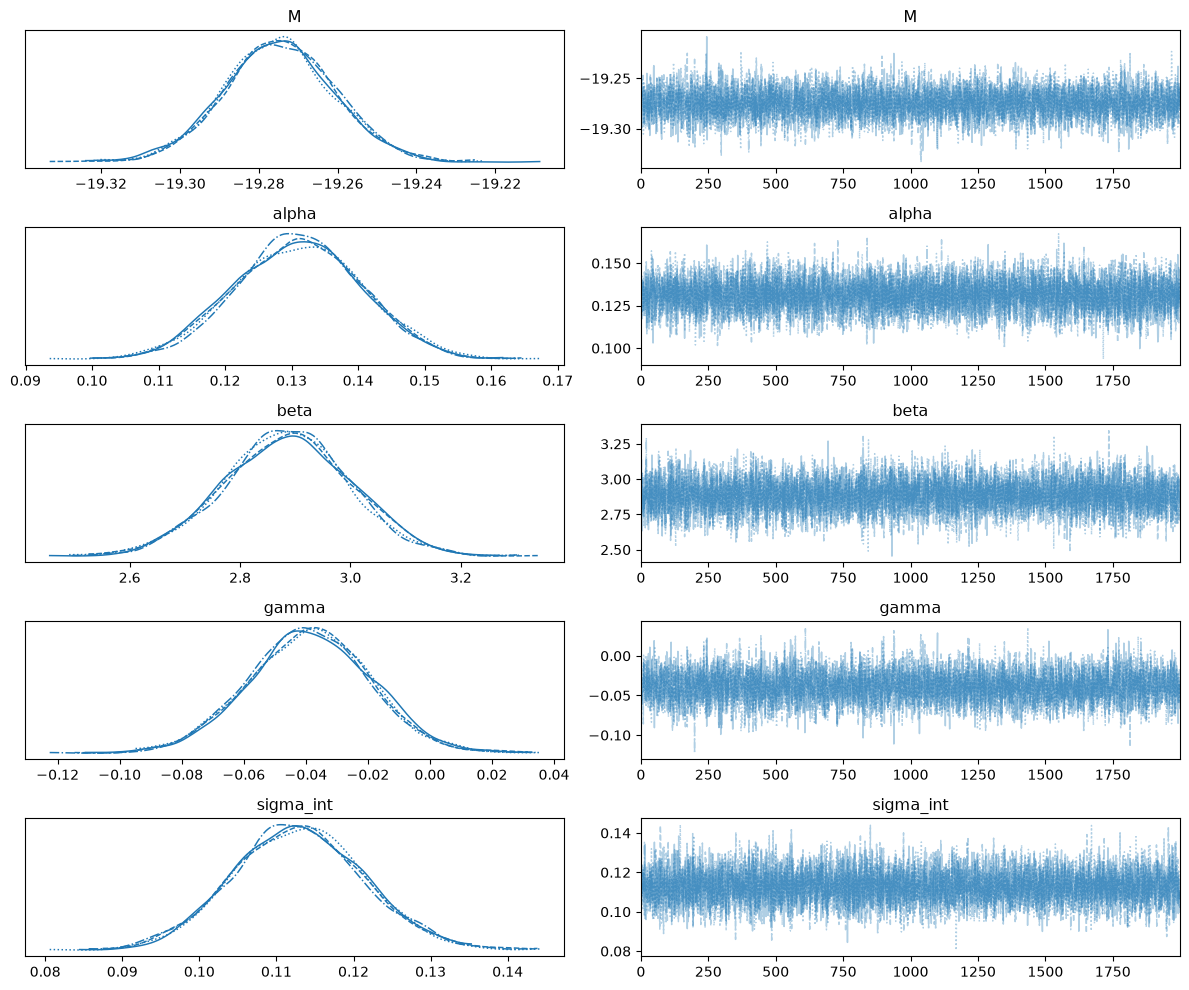

In [18]:
# 2c: your work here
import pymc as pm
import arviz as az

# Use cleaned data from 2b
idx = clean_mask

with pm.Model() as model:

    M = pm.Uniform("M", -21, -17)
    alpha = pm.Uniform("alpha", 0, 0.5)
    beta = pm.Uniform("beta", 0, 6)
    gamma = pm.Uniform("gamma", -0.5, 0.5)
    sigma_int = pm.Uniform("sigma_int", 0, 0.5)

    prediction = (
        M + mu[idx] - alpha*x1[idx]
        + beta*c[idx] + gamma*high_mass[idx]
    )

    variance = (
        mB_err[idx]**2
        + alpha**2*x1_err[idx]**2
        + beta**2*c_err[idx]**2
        + 2*alpha*cov_mB_x1[idx]
        - 2*beta*cov_mB_c[idx]
        - 2*alpha*beta*cov_x1_c[idx]
        + sigma_mu_pec[idx]**2
        + sigma_int**2
    )

    pm.Normal("observed", mu=prediction,
              sigma=pm.math.sqrt(variance), observed=mB[idx])

    map_est = pm.find_MAP(progressbar=False)

    names = ["M", "alpha", "beta", "gamma", "sigma_int"]
    limits = np.array(bounds)
    shifts = 0.10 * (limits[:, 1] - limits[:, 0])

    signs = [[1, 1, 1, 1, 1],
             [-1, -1, -1, -1, -1],
             [1, -1, 1, -1, 1],
             [-1, 1, -1, 1, -1]]

    starts = [
        {name: float(np.clip(map_est[name] + s[j]*shifts[j],
                limits[j, 0]+1e-4, limits[j, 1]-1e-4))
         for j, name in enumerate(names)}
        for s in signs
    ]

    idata = pm.sample(
        draws=2000,
        tune=1500,
        chains=4,
        cores=1,
        initvals=starts,
        random_seed=457,
        target_accept=0.9,
        return_inferencedata=True
    )

units = ["mag", "mag/stretch", "mag/color", "mag", "mag"]

print("MAP estimates (uncertainties from posterior SD):")
for name, unit in zip(names, units):
    values = idata.posterior[name].values.flatten()
    error = np.std(values, ddof=1)
    decimals = max(0, 1-int(np.floor(np.log10(error))))
    print(f"{name}: {map_est[name]:.{decimals}f} "
          f"+/- {error:.{decimals}f} {unit}")

summary = az.summary(idata, var_names=names, kind="diagnostics")
print("\nConvergence diagnostics:")
print(summary[["r_hat", "ess_bulk", "ess_tail"]].round(3))

if (summary["r_hat"] >= 1.01).any() or \
   (summary["ess_bulk"] < 400).any() or \
   (summary["ess_tail"] < 400).any():
    print("\nSome chains may need longer sampling.")
else:
    print("\nAll convergence criteria satisfied.")

az.plot_trace(idata, var_names=names)
plt.tight_layout()
plt.show()

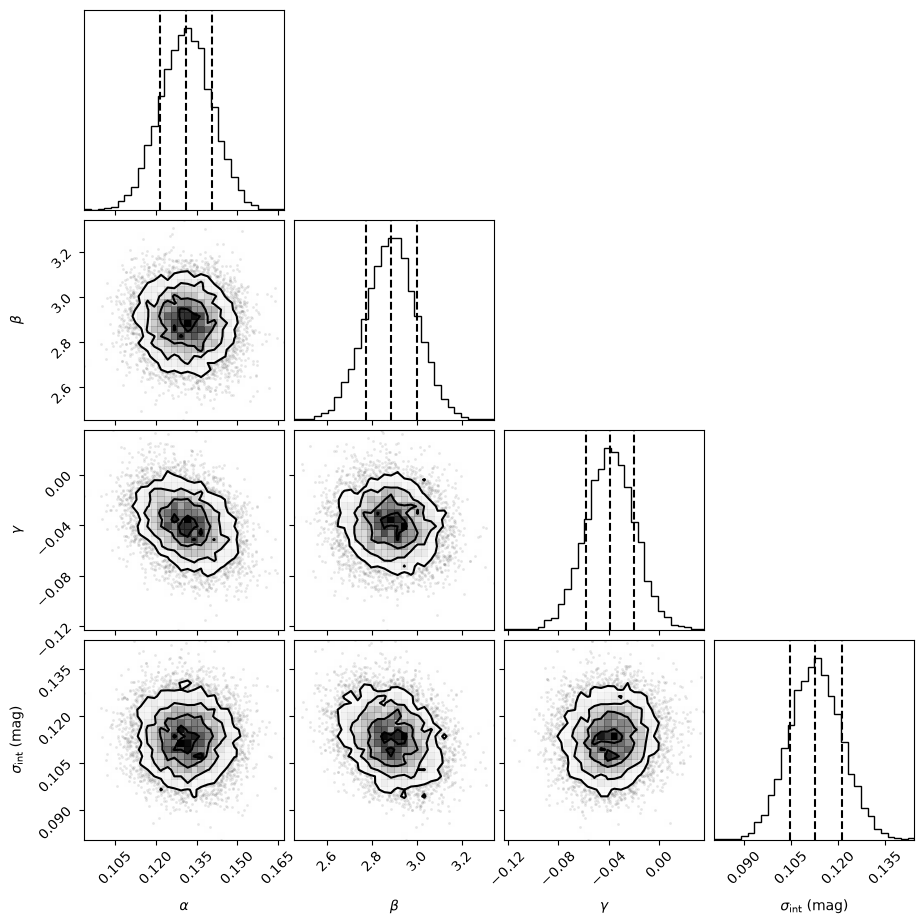

Posterior estimates (median and 68% interval):

alpha = 0.1311 (+0.0095 / -0.0096) mag/stretch
beta = 2.89 (+0.11 / -0.11) mag/color
gamma = -0.039 (+0.019 / -0.019) mag
sigma_int = 0.1127 (+0.0084 / -0.0082) mag


In [19]:
import corner
params = ['alpha', 'beta', 'gamma', 'sigma_int']
units = ['mag/stretch', 'mag/color', 'mag', 'mag']

posterior_samples = np.column_stack([
    idata.posterior[p].values.flatten() for p in params
])

fig = corner.corner(
    posterior_samples,
    labels=[r'$\alpha$', r'$\beta$', r'$\gamma$',
            r'$\sigma_{\rm int}$ (mag)'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=False,
    bins=30
)

plt.show()

print("Posterior estimates (median and 68% interval):\n")

for i, p in enumerate(params):
    q16, q50, q84 = np.percentile(
        posterior_samples[:, i], [16, 50, 84]
    )

    lower = q50 - q16
    upper = q84 - q50

    def format_error(err):
        decimals = max(0, 1 - int(np.floor(np.log10(err))))
        return f"{err:.{decimals}f}", decimals

    lower_str, d1 = format_error(lower)
    upper_str, d2 = format_error(upper)

    decimals = max(d1, d2)

    print(
        f"{p} = {q50:.{decimals}f} "
        f"(+{upper_str} / -{lower_str}) {units[i]}"
    )

Posterior correlations:
M vs alpha: rho = +0.169
M vs beta: rho = +0.110
M vs gamma: rho = -0.758
M vs sigma_int: rho = -0.038
alpha vs beta: rho = -0.073
alpha vs gamma: rho = -0.325
alpha vs sigma_int: rho = -0.056
beta vs gamma: rho = -0.102
beta vs sigma_int: rho = -0.256
gamma vs sigma_int: rho = +0.063


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, beta, gamma, sigma_int]


Output()

Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 7 seconds.



Gamma comparison:
Marginal: gamma = -0.039 (+0.019/-0.019) mag
Fixed M:  gamma = -0.039 (+0.013/-0.013) mag

Marginal sigma_gamma = 0.019 mag
Fixed-M sigma_gamma  = 0.013 mag
Ratio (fixed/marginal) = 0.662

Fixed-M convergence:
           r_hat  ess_bulk  ess_tail
alpha        1.0    6987.0    5673.0
beta         1.0    7393.0    6229.0
gamma        1.0    7599.0    6512.0
sigma_int    1.0    7186.0    5517.0


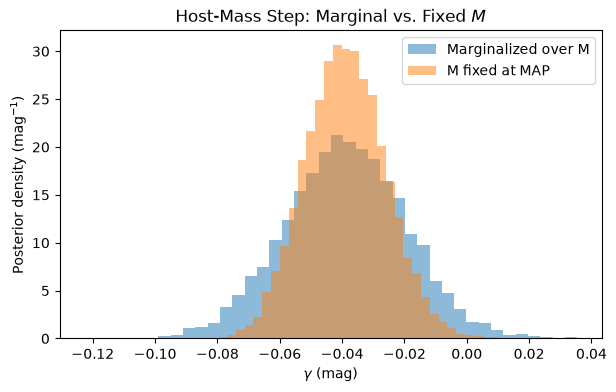

In [20]:
names = ['M', 'alpha', 'beta', 'gamma', 'sigma_int']

full_samples = np.column_stack([
    idata.posterior[p].values.flatten() for p in names
])

corr = np.corrcoef(full_samples, rowvar=False)

print("Posterior correlations:")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        print(f"{names[i]} vs {names[j]}: rho = {corr[i,j]:+.3f}")


M_fixed = float(map_est['M'])
idx = clean_mask

with pm.Model() as fixed_M_model:

    alpha_f = pm.Uniform("alpha", 0, 0.5)
    beta_f = pm.Uniform("beta", 0, 6)
    gamma_f = pm.Uniform("gamma", -0.5, 0.5)
    sigma_f = pm.Uniform("sigma_int", 0, 0.5)

    prediction = (
        M_fixed + mu[idx]
        - alpha_f*x1[idx]
        + beta_f*c[idx]
        + gamma_f*high_mass[idx]
    )

    variance = (
        mB_err[idx]**2
        + alpha_f**2*x1_err[idx]**2
        + beta_f**2*c_err[idx]**2
        + 2*alpha_f*cov_mB_x1[idx]
        - 2*beta_f*cov_mB_c[idx]
        - 2*alpha_f*beta_f*cov_x1_c[idx]
        + sigma_mu_pec[idx]**2
        + sigma_f**2
    )

    pm.Normal(
        "observed",
        mu=prediction,
        sigma=pm.math.sqrt(variance),
        observed=mB[idx]
    )

    fixed_map = pm.find_MAP(progressbar=False)

    idata_fixed = pm.sample(
        draws=2000,
        tune=1500,
        chains=4,
        cores=1,
        target_accept=0.9,
        random_seed=458
    )


gamma_marg = idata.posterior['gamma'].values.flatten()
gamma_fixed = idata_fixed.posterior['gamma'].values.flatten()

def summarize_gamma(samples):
    q16, q50, q84 = np.percentile(samples, [16, 50, 84])
    return q50, q50-q16, q84-q50, np.std(samples, ddof=1)

med_m, lo_m, hi_m, std_m = summarize_gamma(gamma_marg)
med_f, lo_f, hi_f, std_f = summarize_gamma(gamma_fixed)

print("\nGamma comparison:")
print(f"Marginal: gamma = {med_m:.3f} (+{hi_m:.3f}/-{lo_m:.3f}) mag")
print(f"Fixed M:  gamma = {med_f:.3f} (+{hi_f:.3f}/-{lo_f:.3f}) mag")

print(f"\nMarginal sigma_gamma = {std_m:.3f} mag")
print(f"Fixed-M sigma_gamma  = {std_f:.3f} mag")
print(f"Ratio (fixed/marginal) = {std_f/std_m:.3f}")

print("\nFixed-M convergence:")
print(az.summary(
    idata_fixed,
    var_names=['alpha', 'beta', 'gamma', 'sigma_int'],
    kind='diagnostics'
)[['r_hat', 'ess_bulk', 'ess_tail']])

plt.figure(figsize=(7, 4))

plt.hist(gamma_marg, bins=40, density=True, alpha=0.5,
         label='Marginalized over M')
plt.hist(gamma_fixed, bins=40, density=True, alpha=0.5,
         label='M fixed at MAP')

plt.xlabel(r'$\gamma$ (mag)')
plt.ylabel('Posterior density (mag$^{-1}$)')
plt.title(r'Host-Mass Step: Marginal vs. Fixed $M$')
plt.legend()
plt.show()

**ANSWER:**

1. initialized four independent chains around the MAP, offset by 10% of each parameter's prior width with different signs. This is to spread their starting positions more widely than the posterior, which I can check against the sampled posterior uncertainties.
2. I would run the chains longer if any parameter had $\hat R\geq1.01$, bulk ESS below 400 effective draws, or tail ESS below 400 effective draws. I would also inspect the trace plots for drifting behavior or poor mixing. The MAP uncertainties printed by the code are posterior standard deviations, not uncertainties from the optimizer. $\hat R$ is dimensionless, and ESS is measured in effective draws so neither is a physical parameter estimate requiring an error bar.

4. The strongest correlation is between M and $\gamma$, with $\rho=-0.758$ (dimensionless). This occurs because increasing M makes the predicted supernovae fainter, which can be compensated by a more negative host-mass step $\gamma$. There is also a moderate negative correlation between $\alpha$ and $\gamma$, with $\rho=-0.325$ (dimensionless), because stretch and host mass are correlated.

$\frac{\sigma_{\gamma, fixed}}{\sigma_{\gamma, marg}} = 0.66 \sim \sqrt{1-\rho^2}$

Fixing M produces a narrower posterior because it ignores uncertainty in M and its correlation with $\gamma$. The marginalized uncertainty is the appropriate one to report, since M is not known exactly.

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [21]:
# 2d: your work here
def nll1(theta):
    M, alpha, beta, gamma, sigma_int = theta

    r = tripp_residuals(theta)[clean_mask]
    var = total_variance(alpha, beta, sigma_int)[clean_mask]

    if np.any(var <= 0):
        return np.inf

    return 0.5 * np.sum(r**2 / var + np.log(2 * np.pi * var))


def nll0(theta):
    return nll1(np.insert(theta, 3, 0.0))


names = ['M', 'alpha', 'beta', 'gamma', 'sigma_int']
start = np.array([map_est[p] for p in names], dtype=float)

free_idx = [0, 1, 2, 4]

fit1 = minimize(nll1, start, method='L-BFGS-B', bounds=bounds)
fit0 = minimize(nll0, start[free_idx], method='L-BFGS-B',
                bounds=[bounds[i] for i in free_idx])

if not (fit1.success and fit0.success):
    raise RuntimeError(f"Optimization failed: {fit1.message}, {fit0.message}")


def hessian(f, x, steps):
    n = len(x)
    H = np.zeros((n, n))
    f0 = f(x)

    for i in range(n):
        ei = np.zeros(n)
        ei[i] = steps[i]

        H[i, i] = (
            f(x + ei) - 2*f0 + f(x - ei)
        ) / steps[i]**2

        for j in range(i):
            ej = np.zeros(n)
            ej[j] = steps[j]

            H[i, j] = (
                f(x + ei + ej) - f(x + ei - ej)
                - f(x - ei + ej) + f(x - ei - ej)
            ) / (4*steps[i]*steps[j])

            H[j, i] = H[i, j]

    return H


steps = np.array([5e-4, 2e-4, 2e-3, 5e-4, 5e-4])

H1 = hessian(nll1, fit1.x, steps)
H0 = hessian(nll0, fit0.x, steps[free_idx])


def laplace_logZ(fit, H, prior_bounds):
    sign, logdet = np.linalg.slogdet(H)

    if sign <= 0 or np.min(np.linalg.eigvalsh(H)) <= 0:
        raise ValueError("Hessian must be positive definite.")

    d = len(fit.x)
    log_prior_volume = np.sum(
        np.log([hi - lo for lo, hi in prior_bounds])
    )

    return (
        -fit.fun
        - log_prior_volume
        + 0.5*d*np.log(2*np.pi)
        - 0.5*logdet
    )


logZ1 = laplace_logZ(fit1, H1, bounds)
logZ0 = laplace_logZ(fit0, H0, [bounds[i] for i in free_idx])

two_logB = 2*(logZ1 - logZ0)

two_logB_wide = two_logB - 2*np.log(2)

print(f"2 ln B_10 (original prior) = {two_logB:.2f} (dimensionless)")
print(f"2 ln B_10 (double width)  = {two_logB_wide:.2f} (dimensionless)")
print(f"Change in 2 ln B_10       = {-2*np.log(2):.2f} (dimensionless)")


print("\nOriginal prior: evidence favors M0 (no host-mass step).")

2 ln B_10 (original prior) = -2.14 (dimensionless)
2 ln B_10 (double width)  = -3.53 (dimensionless)
Change in 2 ln B_10       = -1.39 (dimensionless)

Original prior: evidence favors M0 (no host-mass step).


In [22]:
N = np.sum(clean_mask)

BIC0 = 4*np.log(N) + 2*fit0.fun

BIC1 = 5*np.log(N) + 2*fit1.fun

delta_BIC = BIC0 - BIC1

print(f"BIC0 = {BIC0:.2f}")
print(f"BIC1 = {BIC1:.2f}")
print(f"BIC0 - BIC1 = {delta_BIC:.2f} (dimensionless)")

BIC0 = -232.36
BIC1 = -230.79
BIC0 - BIC1 = -1.57 (dimensionless)


**ANSWER:**

1. Same prior from 2b: (-0.5,0.5). This is broad enough to allow either sign of the host-mass step and includes the no-step option. When the prior is twice as wide, $2 \ln{B_{1,0}}$ decreases from -2.14 to -3.53 because the wider prior increases the parameter space without improving the max likelihood. Therefore, the wider prior strengthens the evidence in favor of $M_0$.
2. The BIC difference is $BIC_0-BIC_1=-1.57$, which favors $M_0$ (no host-mass step). This is consistent with the Laplace approximation, which gave $2 \ln{B_{1,0}}=-2.14$. Both methods slightly favor the simpler model, but neither provides strong evidence against the host-mass step.
3. $2\ln B_{1,0}=-2.14$ gives positive but modest evidence for $M_0$, while the BIC difference $-1.57$ indicates weak evidence for $M_0$. My measured $\gamma=(-0.039\pm0.019)$ mag is nearly consistent with the published value of $-0.06$ mag, differing by only $1.1\sigma$. A step of $-0.06$ mag would correspond to a $3.2\sigma$ detection at our uncertainty, so our sample could potentially detect a step of that size, although our actual result is only $2.1\sigma$ from zero.

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

Successful fits: 60/60
Failed fits: 0/60

68% interval coverage:
M: 78.3 +/- 5.3%
alpha: 63.3 +/- 6.2%
beta: 75.0 +/- 5.6%
gamma: 65.0 +/- 6.2%
sigma_int: 68.3 +/- 6.0%

True gamma = -0.06 mag (exact input)
Mean recovered gamma = -0.0588 +/- 0.0025 mag
Gamma bias significance = 0.47 sigma

TEST RESULT: PASS


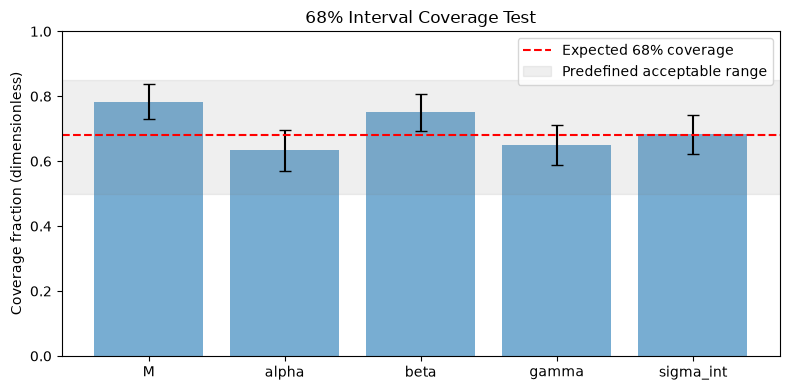

In [23]:
# 2e: your work here
rng = np.random.default_rng(457)
n_sim = 60

names = ['M', 'alpha', 'beta', 'gamma', 'sigma_int']
units = ['mag', 'mag/stretch', 'mag/color', 'mag', 'mag']

truth = np.array([-19.3, 0.13, 2.9, -0.06, 0.11])

idx = clean_mask
mu_sim = mu[idx]
x1_sim = x1[idx]
c_sim = c[idx]
mass_sim = high_mass[idx]

mean_true = (
    truth[0] + mu_sim - truth[1]*x1_sim
    + truth[2]*c_sim + truth[3]*mass_sim
)

var_true = total_variance(
    truth[1], truth[2], truth[4]
)[idx]

def fake_nll(theta, fake_mB):
    M, alpha, beta, gamma, sigma_int = theta

    prediction = (
        M + mu_sim - alpha*x1_sim
        + beta*c_sim + gamma*mass_sim
    )

    var = total_variance(alpha, beta, sigma_int)[idx]

    if np.any(var <= 0):
        return np.inf

    r = fake_mB - prediction
    return 0.5*np.sum(r**2/var + np.log(2*np.pi*var))

estimates = []
errors = []
failed = 0

for k in range(n_sim):

    fake_mB = mean_true + rng.normal(0, np.sqrt(var_true))

    objective = lambda theta: fake_nll(theta, fake_mB)

    fit = minimize(
        objective,
        fit1.x,
        method='L-BFGS-B',
        bounds=bounds
    )

    if not fit.success:
        failed += 1
        continue

    H = hessian(objective, fit.x, steps)

    if np.any(np.linalg.eigvalsh(H) <= 0):
        failed += 1
        continue

    covariance = np.linalg.inv(H)
    sigma = np.sqrt(np.diag(covariance))

    estimates.append(fit.x)
    errors.append(sigma)

estimates = np.array(estimates).reshape(-1, 5)
errors = np.array(errors).reshape(-1, 5)

n_valid = len(estimates)

if n_valid < 2:
    raise RuntimeError("Too few successful fits to assess coverage.")

covered = (
    (truth >= estimates - errors) &
    (truth <= estimates + errors)
)

coverage = covered.mean(axis=0)
coverage_err = np.sqrt(coverage*(1-coverage)/n_valid)

print(f"Successful fits: {n_valid}/{n_sim}")
print(f"Failed fits: {failed}/{n_sim}\n")

print("68% interval coverage:")
for i, name in enumerate(names):
    print(
        f"{name}: {100*coverage[i]:.1f} +/- "
        f"{100*coverage_err[i]:.1f}%"
    )

gamma_mean = estimates[:, 3].mean()
gamma_se = estimates[:, 3].std(ddof=1)/np.sqrt(n_valid)
gamma_bias_z = abs(gamma_mean - truth[3])/gamma_se

print(f"\nTrue gamma = {truth[3]:.2f} mag (exact input)")
print(f"Mean recovered gamma = {gamma_mean:.4f} +/- "
      f"{gamma_se:.4f} mag")
print(f"Gamma bias significance = {gamma_bias_z:.2f} sigma")

coverage_ok = np.all((coverage >= 0.50) & (coverage <= 0.85))
fits_ok = failed/n_sim <= 0.10
bias_ok = gamma_bias_z <= 3

print("\nTEST RESULT:", "PASS" if
      (coverage_ok and fits_ok and bias_ok) else "FAIL")

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(names, coverage, alpha=0.6)
ax.errorbar(
    names, coverage,
    yerr=coverage_err,
    fmt='none', color='black', capsize=4
)

ax.axhline(0.68, color='red', linestyle='--',
           label='Expected 68% coverage')
ax.axhspan(0.50, 0.85, color='gray', alpha=0.12,
           label='Predefined acceptable range')

ax.set_ylabel('Coverage fraction (dimensionless)')
ax.set_ylim(0, 1)
ax.set_title('68% Interval Coverage Test')
ax.legend()
plt.tight_layout()
plt.show()

**ANSWER:**

Closure and coverage test using simulated supernovae. Failure result: A failure if any parameter's coverage falls outside 50–85%, if more than 10% of the fits fail, or if the mean recovered $\gamma$ differs from its true value by more than three standard errors.

Using 60 simulated supernova datasets with known parameters, all 60 fits succeeded. The mean recovered $\gamma=-0.0588\pm0.0025$ mag was consistent with the true value, differing by only $0.47\sigma$. 

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

In [ ]:
#ignoring uncertainties
NETID = 'saumyap2'   # <-- set this
d = np.genfromtxt(f'../../labs/midterm/data/{NETID}/p3_wd_masses.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
mass_err = d['mass_err_Msun'][keep]

fit_err = fit_mix(m, mass_err)

print(f"Median measurement error: {np.median(mass_err):.4f} Msun")
print("Parameters [mu1, sigma1, mu2, sigma2, f]:")
print("Ignoring errors:", np.round(clip_fit, 4))
print("Including errors:", np.round(fit_err, 4))
print("Difference:      ", np.round(fit_err - clip_fit, 4))

plt.figure(figsize=(7, 4))
plt.hist(mass_err, bins=30, alpha=0.7, label='Measurement errors')
plt.axvline(fit_err[1], color='red', ls='--',
            label=r'Intrinsic $\sigma_1$')
plt.axvline(fit_err[3], color='green', ls='--',
            label=r'Intrinsic $\sigma_2$')
plt.xlabel(r'Mass uncertainty ($M_\odot$)')
plt.ylabel('Number of stars')
plt.legend()
plt.show()

In [ ]:
import emcee

names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']

def log_prob(p):
    mu1, s1, mu2, s2, f = p
    if not (0.3 < mu1 < 1.3 and 0.3 < mu2 < 1.3
            and 0.005 < s1 < 0.5 and 0.005 < s2 < 0.5
            and 0 < f < 1):
        return -np.inf

    a = np.log(f) + norm.logpdf(m, mu1, s1)
    b = np.log1p(-f) + norm.logpdf(m, mu2, s2)
    return np.logaddexp(a, b).sum()

def old_rhat(x):
    n = len(x)
    B = n * np.var(x.mean(axis=0), ddof=1)
    W = np.mean(np.var(x, axis=0, ddof=1))
    return np.sqrt((n-1)/n + B/(n*W))

rng = np.random.default_rng(457)
offsets = np.array([
    [0, 0, 0, 0, 0],
    [-0.04, 0.02, 0.06, 0.02, -0.10],
    [0.04, 0.02, -0.06, 0.03, 0.10],
    [-0.03, 0.03, 0.08, 0.02, 0.05]
])

bounds = np.array([
    [0.3, 1.3], [0.005, 0.5],
    [0.3, 1.3], [0.005, 0.5], [0.001, 0.999]
])

chains = []

for k in range(4):
    center = np.clip(p0 + offsets[k],
                     bounds[:, 0]+0.01, bounds[:, 1]-0.01)
    start = center + 1e-3*rng.normal(size=(32, 5))

    sampler = emcee.EnsembleSampler(32, 5, log_prob)
    sampler.run_mcmc(start, 3000, progress=False)
    chains.append(sampler.get_chain(discard=500))

original = [old_rhat(chains[0][:, :, j]) for j in range(5)]

independent = np.array([ch[:, 0, :] for ch in chains])

for ch in independent:
    swap = ch[:, 0] > ch[:, 2]
    old = ch[swap].copy()
    ch[swap] = old[:, [2, 3, 0, 1, 4]]
    ch[swap, 4] = 1 - old[:, 4]

idata_wd = az.from_dict(posterior={
    name: independent[:, :, j] for j, name in enumerate(names)
})

diag = az.summary(idata_wd, kind='diagnostics')

print("Parameter  Original Rhat  Independent Rhat  Bulk ESS")
for j, name in enumerate(names):
    print(f"{name:7s}    {original[j]:.3f}          "
          f"{diag.loc[name, 'r_hat']:.3f}             "
          f"{diag.loc[name, 'ess_bulk']:.0f}")

az.plot_trace(idata_wd, var_names=['mu2', 'f'])
plt.show()

**REFEREE REPORT:**

1. **Outlier clipping:** The ai removes observations beyond three standard deviations from the median before fitting. This may remove real, high-mass white dwarfs, biasing the population fractions and suppressing the component the model is supposed to investigate.

The original notebook removed 14 of the 600 white dwarfs, including 13 with masses above $0.9 M_\odot$. This is concerning because the high-mass population is what the analysis is trying to investigate and this cuts them out. Clipping also lowers the inferred mean and width of the broad, higher-mass component. This demonstrates that the clipping procedure changes the result rather than just removing bad measurements. 

The correct treatment is to keep the full sample unless there is independent evidence that particular mass measurements are unreliable. A mixture model should account for the different populations instead of removing stars based solely on their masses.

2. **Ignoring measurement uncertainties:** The likelihood does not use the individual mass errors. Each Gaussian component should account for both intrinsic scatter and observational uncertainty through $\sigma_{obs,i}^2=\sigma_{pop}^2+\sigma_{m,i}^2$. Ignoring these errors can bias the inferred population widths.

Ignoring measurement errors widens the narrow component's inferred intrinsic width by about $0.0029M_\odot$. The broad component changes very little because its intrinsic width is much larger than the typical measurement uncertainty. 

The correct treatment is to include the individual mass measurement variance in each Gaussian component: $\sigma_{total,i,k}^2 = \sigma_k^2 + \sigma_{m,i}^2$

4. **Unreliable convergence diagnostics:** The notebook treats walkers from a single `emcee` ensemble as independent chains when calculating $\hat R$. Since the walkers are correlated and initialized close together, apparently good convergence may not indicate that the full posterior has been explored.

Even the ai's diagnostic indicates nonconvergence. The independent ensembles confirm this, with $\hat R$ well above the desired threshold of 1.01 and extremely low effective sample sizes. The trace plots show that different ensembles remain in distinct regions of parameter space, including different solutions for the high-mass component and its mixture fraction.

The correct treatment is to run independently initialized ensembles, resolve the mixture-component labeling ambiguity, and assess convergence using $\hat R$, effective sample sizes, and trace plots. If the ensembles remain separated, combined posterior uncertainties are not trustworthy. This error one has not yet been fully corrected: the diagnostic demonstrated that more sampling or a better sampling strategy is needed.

In [ ]:
mass = d['mass_Msun']
err = d['mass_err_Msun']
corrected_fit = fit_mix(mass, err)

def corrected_logp(p):
    mu1, s1, mu2, s2, f = p

    if not (0.3 < mu1 < mu2 < 1.3 and
            0.005 < s1 < 0.5 and 0.005 < s2 < 0.5 and
            0 < f < 1):
        return -np.inf

    a = np.log(f) + norm.logpdf(mass, mu1, np.hypot(s1, err))
    b = np.log1p(-f) + norm.logpdf(mass, mu2, np.hypot(s2, err))
    return np.logaddexp(a, b).sum()

centers = [
    corrected_fit,
    [0.58, 0.04, 0.72, 0.18, 0.40],
    [0.59, 0.06, 0.86, 0.08, 0.80],
    [0.60, 0.08, 0.88, 0.06, 0.75]
]

rng = np.random.default_rng(457)
chains = []

for k, center in enumerate(centers):
    start = np.array(center) + rng.normal(
        0, [0.002, 0.002, 0.003, 0.003, 0.01], (32, 5)
    )

    np.random.seed(457 + k)
    sampler = emcee.EnsembleSampler(32, 5, corrected_logp)
    sampler.run_mcmc(start, 4000, progress=True)

    chains.append(sampler.get_chain(discard=1000)[:, 0, :])

chains = np.array(chains)

names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']
idata_corrected = az.from_dict(posterior={
    name: chains[:, :, j] for j, name in enumerate(names)
})

diag = az.summary(idata_corrected, kind='diagnostics')

print("Corrected MLE:", np.round(corrected_fit, 4))
print("\nIndependent-ensemble diagnostics:")
print(diag[['r_hat', 'ess_bulk', 'ess_tail']])

converged = (
    (diag['r_hat'] < 1.01).all()
    and (diag['ess_bulk'] > 400).all()
    and (diag['ess_tail'] > 400).all()
)

print("\nConvergence:", "PASS" if converged else "NOT YET CONVERGED")

az.plot_trace(idata_corrected, var_names=['mu2', 'f'])
plt.tight_layout()
plt.show()

Outlier clipping: I corrected the analysis by keeping the full sample. Keeping the previously removed stars avoids artificially suppressing the high-mass population.

Measurement uncertainties: I corrected the likelihood by including each star's measurement variance, using $\sigma_{obs,i,k}^2=\sigma_k^2+\sigma_{m,i}^2$. This reduced the narrow population's estimated intrinsic width from $0.0317$ to $0.0288M_\odot$ in the clipped sample, while the broader population changed very little. This shows that ignoring measurement errors mainly affects the narrower component.

Convergence diagnostics: I ran four independently initialized MCMC ensembles and imposed $\mu_1<\mu_2$ to prevent label switching. The corrected trace plots show much better agreement between ensembles than the original analysis. However, $\hat R$ remains approximately 1.01–1.02, and bulk ESS is only 152–206 effective draws. Thus, convergence has improved but does not yet satisfy my criteria, and further sampling is needed before trusting the final posterior uncertainties.

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

ChatGPT
Prompts:

- Writing print statements and plotting code

- Writing tests, and making functions

- Used ai to help code the demonstrations

- Used to implement the Pymc sampling method and making the corner plots in 2c.

- Helping write the Laplace approximation and BIC comparison code in Part 2d.

- Helping construct the simulation and coverage tests in Part 2e.

- Used to help interpret some of the plots/results/

- Check my results and help identify anything that needs further testing or explanation.

It initially said that $\alpha$ and $\beta$ showed a positive correlation. However, when I calculated the correlation coefficients, $\rho_{\alpha,\beta}=-0.073$, showing that they were nearly uncorrelated.

Without checking the AI output, I  could have interpreted the nonzero estimate of $\gamma$ as sufficient evidence for a host-mass step, but checking the Laplace approximation and BIC showed that the simpler no-step model was slightly favored.

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.